1. Import dan membaca dataset

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from pathlib import Path
from functools import lru_cache
from IPython.display import display
from rank_bm25 import BM25Okapi
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

pd.set_option("display.max_colwidth", 120)

# Mendukung menjalankan notebook dari folder ARTIKEL (1) atau Eksperiment1
CWD = Path.cwd().resolve()
ROOT = next(
    (p for p in [CWD, *CWD.parents]
     if all((p / f).is_file() for f in (
         "corpus_faq.csv", "kamus_normalisasi.csv", "queries_dev.csv", "queries_test.csv"
     ))),
    None
)
if ROOT is None:
    raise FileNotFoundError(
        "Folder ARTIKEL (1) tidak ditemukan dari working directory: " + str(CWD)
    )

corpus = pd.read_csv(ROOT / "corpus_faq.csv")
kamus = pd.read_csv(ROOT / "kamus_normalisasi.csv")
dev_df = pd.read_csv(ROOT / "queries_dev.csv")
test_df = pd.read_csv(ROOT / "queries_test.csv")

OUTPUT_DIR = ROOT / "Eksperiment1" / "hasil_exp1"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for nama, df, wajib in (
    ("Corpus", corpus, ["doc_id", "pertanyaan_baku", "jawaban"]),
    ("Kamus", kamus, ["tidak_baku", "baku"]),
    ("Dev", dev_df, ["query_id", "query_text", "gaya_kueri", "relevant_doc_id"]),
    ("Test", test_df, ["query_id", "query_text", "gaya_kueri", "relevant_doc_id"]),
):
    hilang = set(wajib) - set(df.columns)
    if hilang:
        raise ValueError(f"Kolom {nama} tidak ditemukan: {sorted(hilang)}")

if not set(dev_df["query_id"]).isdisjoint(set(test_df["query_id"])):
    raise ValueError("Dev dan test memuat query_id yang sama; periksa split sebelumnya.")

print(f"Corpus  : {corpus.shape}")
print(f"Kamus   : {kamus.shape}")
print(f"Dev set : {dev_df.shape}")
print(f"Test set: {test_df.shape}")
print(f"Output  : {OUTPUT_DIR}")

Corpus  : (40, 4)
Kamus   : (73, 3)
Dev set : (166, 7)
Test set: (499, 7)
Output  : D:\Folder KULIAH\Sistem Temu Kembali\Artikel (1)\Eksperiment1\hasil_exp1


2. Praproses standar dan indeks BM25

In [2]:
stemmer = StemmerFactory().create_stemmer()
stopwords_id = set(StopWordRemoverFactory().get_stop_words())

@lru_cache(maxsize=None)
def stem_cached(token):
    return stemmer.stem(token)

def case_fold(text):
    return str(text).lower()

def clean_regex(text):
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def tokenize(text):
    return text.split()

def remove_stopwords(tokens):
    return [t for t in tokens if t not in stopwords_id]

def preprocess_standard(text, do_stem=True, do_stopword=True):
    tokens = tokenize(clean_regex(case_fold(text)))
    if do_stopword:
        tokens = remove_stopwords(tokens)
    if do_stem:
        tokens = [stem_cached(t) for t in tokens]
    return tokens

# Dokumen corpus sama dengan Eksperimen 2: pertanyaan_baku + jawaban
corpus["teks_indeks"] = (
    corpus["pertanyaan_baku"].fillna("").astype(str)
    + " "
    + corpus["jawaban"].fillna("").astype(str)
)
corpus["tokens"] = corpus["teks_indeks"].apply(preprocess_standard)
corpus_tokens = corpus["tokens"].tolist()
doc_ids = corpus["doc_id"].astype(str).tolist()

# rank_bm25 default: k1=1.5 dan b=0.75 (sama dengan Eksperimen 2)
bm25 = BM25Okapi(corpus_tokens)

if len(set(doc_ids)) != len(doc_ids):
    raise ValueError("doc_id FAQ tidak unik.")
for label, df in [("Dev", dev_df), ("Test", test_df)]:
    unknown = set(df["relevant_doc_id"].astype(str)) - set(doc_ids)
    if unknown:
        raise ValueError(f"{label}: ID FAQ relevan tidak dikenali: {sorted(unknown)}")

# Verifikasi sampel token yang sudah disimpan pada file split
if "tokens_baseline" in dev_df.columns:
    import ast
    salah = sum(
        preprocess_standard(row["query_text"]) != ast.literal_eval(row["tokens_baseline"])
        for _, row in dev_df.iterrows()
    )
    print(f"Perbedaan preprocessing dengan tokens_baseline (dev): {salah}")
    if salah:
        raise ValueError("Preprocessing berbeda dari baseline. Samakan sebelum evaluasi.")

print(f"Jumlah dokumen FAQ: {len(doc_ids)}")
print(f"Rata-rata panjang dokumen BM25: {bm25.avgdl:.2f}")

Perbedaan preprocessing dengan tokens_baseline (dev): 0
Jumlah dokumen FAQ: 40
Rata-rata panjang dokumen BM25: 26.23


3. Normalisasi berbasis kamus

In [3]:
# Padanan kosong dan ambigu (mis. 'kita/anda') tidak ditebak secara otomatis.
# Padanan multi-kata dan pola multi-token seperti 'pj pi' tetap didukung.
pasangan_kamus = []
entri_dilewati = []
seen = {}
for nomor, row in kamus.iterrows():
    asal_raw, baku_raw = row["tidak_baku"], row["baku"]
    if pd.isna(asal_raw) or pd.isna(baku_raw) or "/" in str(baku_raw):
        entri_dilewati.append((nomor, asal_raw, baku_raw))
        continue

    asal = tuple(tokenize(clean_regex(case_fold(asal_raw))))
    tujuan = tuple(tokenize(clean_regex(case_fold(baku_raw))))
    if not asal or not tujuan:
        entri_dilewati.append((nomor, asal_raw, baku_raw))
        continue
    if asal in seen and seen[asal] != tujuan:
        raise ValueError(f"Padanan kamus bertentangan untuk '{' '.join(asal)}'")
    if asal not in seen:
        pasangan_kamus.append((asal, tujuan))
        seen[asal] = tujuan

# Prioritaskan frasa sumber terpanjang agar dapat memproses 'pj pi' utuh
pasangan_kamus.sort(key=lambda p: (-len(p[0]), p[0]))

def ganti_kamus(tokens):
    """Ganti token/frasa yang ditemukan, tanpa menebak typo di luar kamus.

    Mengembalikan token permukaan sesudah kamus dan log perubahan.
    """
    hasil, log, i = [], [], 0
    while i < len(tokens):
        ditemukan = False
        for asal, tujuan in pasangan_kamus:
            n = len(asal)
            if tuple(tokens[i:i+n]) == asal:
                hasil.extend(tujuan)
                log.append({
                    "asal": " ".join(asal),
                    "tujuan": " ".join(tujuan),
                    "n_token_asal": len(asal),
                    # Agar rasio memakai denominator yang sama dengan Eksperimen 2:
                    # token kueri sebelum normalisasi setelah stopword removal dasar.
                    "n_token_terkoreksi": sum(t not in stopwords_id for t in asal)
                })
                i += n
                ditemukan = True
                break
        if not ditemukan:
            hasil.append(tokens[i])
            i += 1
    return hasil, log

def preprocess_kamus(text, gunakan_kamus=True):
    # Sama dengan alur baseline, tetapi kamus disisipkan sebelum stopword dan stemming
    token_awal = tokenize(clean_regex(case_fold(text)))
    if gunakan_kamus:
        token_normal, log = ganti_kamus(token_awal)
    else:
        token_normal, log = token_awal, []
    token_final = [stem_cached(t) for t in remove_stopwords(token_normal)]
    return token_final, log

print(f"Entri kamus awal: {len(kamus)}")
print(f"Entri kamus valid: {len(pasangan_kamus)}")
print(f"Entri dilewati (kosong/ambigu): {len(entri_dilewati)}")
if entri_dilewati:
    display(pd.DataFrame(entri_dilewati, columns=["baris_0based", "tidak_baku", "baku"]))

Entri kamus awal: 73
Entri kamus valid: 68
Entri dilewati (kosong/ambigu): 5


,baris_0based,tidak_baku,baku
0,64,mi,NaN
1,65,ki,NaN
2,66,ji,NaN
3,67,ta,kita/anda
4,69,tabe,permisi/maaf


4. Contoh perubahan kueri

In [4]:
# Sampel dev, bukan test, supaya melihat proses kamus tanpa melihat data evaluasi akhir
sampel = dev_df[dev_df["gaya_kueri"].isin(["singkatan", "informal"])].head(8)

for _, row in sampel.iterrows():
    token_kamus, log = preprocess_kamus(row["query_text"], gunakan_kamus=True)
    print(f"[{row['query_id']}] Asli    : {row['query_text']}")
    print("        Kamus   : " + (", ".join(f"{x['asal']} -> {x['tujuan']}" for x in log) if log else "(tidak ada padanan kamus)"))
    print(f"        BM25 Tok: {token_kamus}\n")

[Q0038] Asli    : teman kelompok ku masih belum join dipengelompokan tapi sudah disetujui oleh admin
        Kamus   : (tidak ada padanan kamus)
        BM25 Tok: ['teman', 'kelompok', 'ku', 'join', 'kelompok', 'tuju', 'admin']

[Q0182] Asli    : mau tanya, apa untuk mahasiswa Prodi Teknik Komputer yang sedang melaksanakan PI, mata kuliah PI wajib diprogramkan semester depan atau semester 7
        Kamus   : pi -> praktik industri, pi -> praktik industri
        BM25 Tok: ['mau', 'tanya', 'apa', 'mahasiswa', 'prodi', 'teknik', 'komputer', 'sedang', 'laksana', 'praktik', 'industri', 'mata', 'kuliah', 'praktik', 'industri', 'wajib', 'program', 'semester', 'depan', 'semester', '7']

[Q0042] Asli    : tempat pi ku ga ada di list sipi, gmn caranya nambahin
        Kamus   : pi -> praktik industri, ga -> tidak, sipi -> sistem informasi praktik industri, gmn -> bagaimana
        BM25 Tok: ['tempat', 'praktik', 'industri', 'ku', 'list', 'sistem', 'informasi', 'praktik', 'industri', 'bagaimana'

5. Evaluasi Baseline vs Kamus pada Development Set

In [5]:
def evaluate_kamus(df, bm25_index, doc_ids_list, gunakan_kamus=False, return_detail=False):
    """Metrik dan format keluaran selaras dengan evaluate_levenshtein Eksperimen 2."""
    if len(df) == 0:
        raise ValueError("Data evaluasi kosong.")

    hit1 = hit3 = hit5 = 0
    reciprocal_ranks = []
    total_tokens = 0
    corrected_count = 0
    matched_entries = 0
    details = []

    for _, row in df.iterrows():
        query_text = row["query_text"]
        # Denominator sesuai Eksperimen 2: token mentah non-stopword sebelum koreksi
        token_sumber = remove_stopwords(tokenize(clean_regex(case_fold(query_text))))
        total_tokens += len(token_sumber)

        token_final, log = preprocess_kamus(query_text, gunakan_kamus)
        corrected_count += sum(x["n_token_terkoreksi"] for x in log)
        matched_entries += len(log)

        scores = bm25_index.get_scores(token_final)
        ranked_idx = np.argsort(scores)[::-1]  # sama dengan Eksperimen 2
        ranked_docs = [doc_ids_list[i] for i in ranked_idx]
        true_doc = str(row["relevant_doc_id"])
        rank = ranked_docs.index(true_doc) + 1

        hit1 += int(rank == 1)
        hit3 += int(rank <= 3)
        hit5 += int(rank <= 5)
        reciprocal_ranks.append(1 / rank)

        details.append({
            "query_id": row["query_id"],
            "gaya_kueri": row["gaya_kueri"],
            "query_text": query_text,
            "relevant_doc_id": true_doc,
            "prediksi_top1": ranked_docs[0],
            "peringkat_benar": rank,
            "skor_top1": float(scores[ranked_idx[0]]),
            "hit1": int(rank == 1),
            "rr": 1 / rank,
            "tokens_bm25": " ".join(token_final),
            "normalisasi": " | ".join(f"{x['asal']} -> {x['tujuan']}" for x in log),
            "jumlah_penggantian": len(log),
            "token_terkoreksi": sum(x["n_token_terkoreksi"] for x in log)
        })

    n = len(df)
    ringkasan = {
        "Hit@1": hit1 / n,
        "Hit@3": hit3 / n,
        "Hit@5": hit5 / n,
        "MRR": float(np.mean(reciprocal_ranks)),
        "Token_Terkoreksi": corrected_count,
        "Rasio_Koreksi": corrected_count / max(total_tokens, 1),
        "n": n
    }
    if return_detail:
        return ringkasan, pd.DataFrame(details)
    return ringkasan

# Tidak ada threshold d untuk kamus. Bandingkan dua konfigurasi pada dev set.
dev_baseline, detail_base_dev = evaluate_kamus(dev_df, bm25, doc_ids, False, True)
dev_kamus, detail_kamus_dev = evaluate_kamus(dev_df, bm25, doc_ids, True, True)

singkatan_dev = dev_df[dev_df["gaya_kueri"] == "singkatan"]
res_singkatan_base = evaluate_kamus(singkatan_dev, bm25, doc_ids, False)
res_singkatan_kamus = evaluate_kamus(singkatan_dev, bm25, doc_ids, True)

tabel_dev = pd.DataFrame([
    {"Konfigurasi": "Baseline (BM25 Tanpa Normalisasi)", **dev_baseline,
     "Hit@1_Singkatan": res_singkatan_base["Hit@1"], "MRR_Singkatan": res_singkatan_base["MRR"]},
    {"Konfigurasi": "BM25 + Normalisasi Kamus", **dev_kamus,
     "Hit@1_Singkatan": res_singkatan_kamus["Hit@1"], "MRR_Singkatan": res_singkatan_kamus["MRR"]}
])
print("=== Perbandingan Baseline dan Kamus pada Development Set ===")
display(tabel_dev.round(4))

=== Perbandingan Baseline dan Kamus pada Development Set ===


,Konfigurasi,Hit@1,Hit@3,Hit@5,MRR,Token_Terkoreksi,Rasio_Koreksi,n,Hit@1_Singkatan,MRR_Singkatan
0,Baseline (BM25 Tanpa Normalisasi),0.9398,0.9819,0.988,0.9620,0,0.0000,166,0.9143,0.9476
1,BM25 + Normalisasi Kamus,0.9096,0.9759,0.994,0.9443,273,0.1712,166,0.9143,0.9524


6. Visualisasi pada Development Set

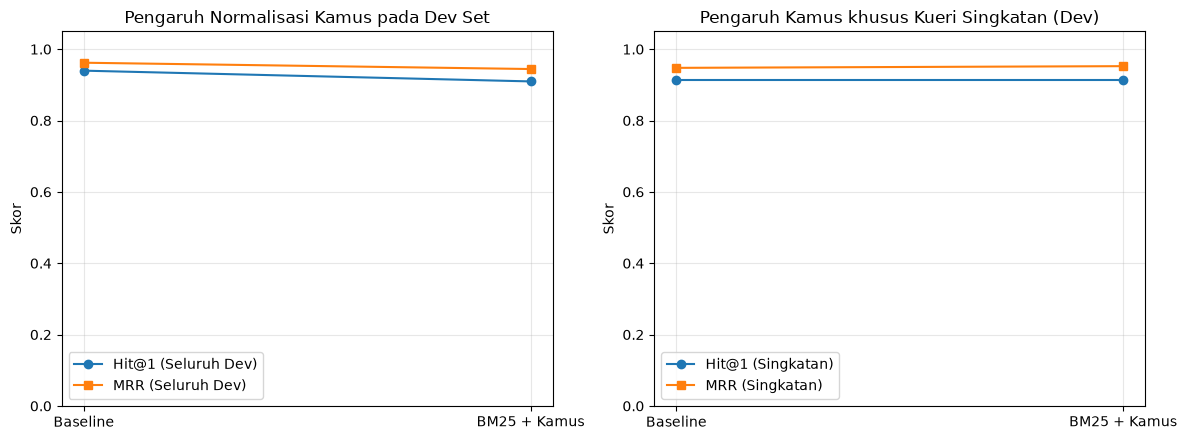

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
label_dev = ["Baseline", "BM25 + Kamus"]
x_dev = np.arange(2)

ax[0].plot(x_dev, tabel_dev["Hit@1"], marker="o", label="Hit@1 (Seluruh Dev)")
ax[0].plot(x_dev, tabel_dev["MRR"], marker="s", label="MRR (Seluruh Dev)")
ax[0].set_title("Pengaruh Normalisasi Kamus pada Dev Set")
ax[0].set_ylabel("Skor")
ax[0].set_xticks(x_dev, label_dev)
ax[0].set_ylim(0, 1.05)
ax[0].grid(alpha=0.3)
ax[0].legend()

ax[1].plot(x_dev, tabel_dev["Hit@1_Singkatan"], marker="o", label="Hit@1 (Singkatan)")
ax[1].plot(x_dev, tabel_dev["MRR_Singkatan"], marker="s", label="MRR (Singkatan)")
ax[1].set_title("Pengaruh Kamus khusus Kueri Singkatan (Dev)")
ax[1].set_xticks(x_dev, label_dev)
ax[1].set_ylabel("Skor")
ax[1].set_ylim(0, 1.05)
ax[1].grid(alpha=0.3)
ax[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig_kamus_dev.png", dpi=150)
plt.show()

7.  Evaluasi keseluruhan dan per gaya kueri pada Test Set

In [7]:
order = ["formal", "informal", "singkatan", "parafrase", "typo"]

# Tidak melakukan tuning apa pun menggunakan test set.
test_baseline, detail_base_test = evaluate_kamus(test_df, bm25, doc_ids, False, True)
test_kamus, detail_kamus_test = evaluate_kamus(test_df, bm25, doc_ids, True, True)

summary_test = pd.DataFrame([
    {"Konfigurasi": "Baseline (BM25 Tanpa Normalisasi)", **test_baseline},
    {"Konfigurasi": "BM25 + Normalisasi Kamus", **test_kamus}
])
print(f"=== Perbandingan Kinerja Keseluruhan pada Test Set (n = {len(test_df)}) ===")
display(summary_test.round(4))

per_gaya_rows = []
for gaya in order:
    sub = test_df[test_df["gaya_kueri"] == gaya]
    if len(sub) == 0:
        continue
    b_res = evaluate_kamus(sub, bm25, doc_ids, False)
    k_res = evaluate_kamus(sub, bm25, doc_ids, True)
    per_gaya_rows.append({
        "Gaya Kueri": gaya,
        "n": len(sub),
        "Hit@1_Baseline": b_res["Hit@1"],
        "Hit@1_Kamus": k_res["Hit@1"],
        "Delta_Hit@1": k_res["Hit@1"] - b_res["Hit@1"],
        "MRR_Baseline": b_res["MRR"],
        "MRR_Kamus": k_res["MRR"],
        "Delta_MRR": k_res["MRR"] - b_res["MRR"],
        "Rasio_Token_Dikoreksi": k_res["Rasio_Koreksi"]
    })

per_gaya_df = pd.DataFrame(per_gaya_rows)
print("\n=== Perbandingan Kinerja per Gaya Kueri pada Test Set (Normalisasi Kamus) ===")
display(per_gaya_df.round(4))

=== Perbandingan Kinerja Keseluruhan pada Test Set (n = 499) ===


,Konfigurasi,Hit@1,Hit@3,Hit@5,MRR,Token_Terkoreksi,Rasio_Koreksi,n
0,Baseline (BM25 Tanpa Normalisasi),0.9519,0.988,0.994,0.9698,0,0.0000,499
1,BM25 + Normalisasi Kamus,0.8397,0.976,0.986,0.9044,899,0.1786,499



=== Perbandingan Kinerja per Gaya Kueri pada Test Set (Normalisasi Kamus) ===


,Gaya Kueri,n,Hit@1_Baseline,Hit@1_Kamus,Delta_Hit@1,MRR_Baseline,MRR_Kamus,Delta_MRR,Rasio_Token_Dikoreksi
0,formal,59,0.9661,0.8644,-0.1017,0.9753,0.9214,-0.0539,0.0890
1,informal,109,1.0000,0.8532,-0.1468,1.0000,0.9148,-0.0852,0.1896
2,singkatan,107,0.9720,0.8785,-0.0935,0.9825,0.9330,-0.0495,0.3362
3,parafrase,104,0.8654,0.7981,-0.0673,0.9186,0.8720,-0.0466,0.0969
4,typo,120,0.9583,0.8167,-0.1417,0.9727,0.8892,-0.0834,0.1265


8. Grafik Test Set dan simpan hasil

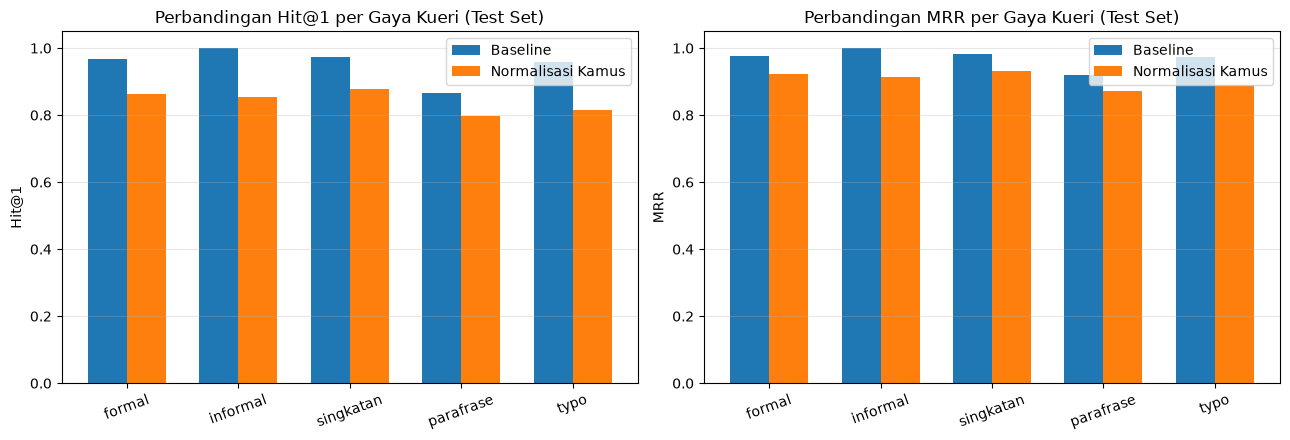

Hasil tabel dan grafik tersimpan di: D:\Folder KULIAH\Sistem Temu Kembali\Artikel (1)\Eksperiment1\hasil_exp1


In [ ]:
x = np.arange(len(per_gaya_df))
width = 0.35

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(x - width/2, per_gaya_df["Hit@1_Baseline"], width, label="Baseline")
ax[0].bar(x + width/2, per_gaya_df["Hit@1_Kamus"], width, label="Normalisasi Kamus")
ax[0].set_title("Perbandingan Hit@1 per Gaya Kueri (Test Set)")
ax[0].set_xticks(x, per_gaya_df["Gaya Kueri"], rotation=20)
ax[0].set_ylim(0, 1.05)
ax[0].set_ylabel("Hit@1")
ax[0].grid(axis="y", alpha=0.3)
ax[0].legend()

ax[1].bar(x - width/2, per_gaya_df["MRR_Baseline"], width, label="Baseline")
ax[1].bar(x + width/2, per_gaya_df["MRR_Kamus"], width, label="Normalisasi Kamus")
ax[1].set_title("Perbandingan MRR per Gaya Kueri (Test Set)")
ax[1].set_xticks(x, per_gaya_df["Gaya Kueri"], rotation=20)
ax[1].set_ylim(0, 1.05)
ax[1].set_ylabel("MRR")
ax[1].grid(axis="y", alpha=0.3)
ax[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig_exp1_kamus_vs_baseline_test.png", dpi=150)
plt.show()

tabel_dev.to_csv(OUTPUT_DIR / "hasil_evaluasi_kamus_dev.csv", index=False)
summary_test.to_csv(OUTPUT_DIR / "hasil_ringkasan_kamus_test.csv", index=False)
per_gaya_df.to_csv(OUTPUT_DIR / "hasil_per_gaya_kamus_test.csv", index=False)
detail_base_test.to_csv(OUTPUT_DIR / "detail_baseline_test.csv", index=False)
detail_kamus_test.to_csv(OUTPUT_DIR / "detail_kamus_test.csv", index=False)

print(f"Hasil tabel dan grafik tersimpan di: {OUTPUT_DIR}")

9. Analisis kasus naik/turun peringkat pada Test Set

In [9]:
# Sama tujuan dengan sel terakhir Eksperimen 2, tetapi memakai normalisasi kamus
perbandingan_kasus = detail_base_test[[
    "query_id", "gaya_kueri", "query_text", "relevant_doc_id",
    "tokens_bm25", "peringkat_benar", "prediksi_top1"
]].merge(
    detail_kamus_test[[
        "query_id", "tokens_bm25", "peringkat_benar", "prediksi_top1",
        "normalisasi", "jumlah_penggantian", "token_terkoreksi"
    ]], on="query_id", suffixes=("_base", "_kamus"), validate="one_to_one"
)

perbandingan_kasus["status"] = np.select(
    [
        perbandingan_kasus["peringkat_benar_kamus"] < perbandingan_kasus["peringkat_benar_base"],
        perbandingan_kasus["peringkat_benar_kamus"] > perbandingan_kasus["peringkat_benar_base"]
    ],
    ["Membaik", "Memburuk"],
    default="Tetap"
)
perubahan_df = perbandingan_kasus[perbandingan_kasus["status"] != "Tetap"].copy()

print(f"Total kueri dengan perubahan peringkat dokumen relevan: {len(perubahan_df)}")
if len(perubahan_df):
    display(perubahan_df["status"].value_counts())
    display(perubahan_df.head(15))
else:
    print("Tidak ada kueri yang berubah peringkat dokumen relevannya.")

perubahan_df.to_csv(OUTPUT_DIR / "kasus_perubahan_peringkat_kamus_test.csv", index=False)
audit_kamus = detail_kamus_test[detail_kamus_test["jumlah_penggantian"] > 0].copy()
audit_kamus.to_csv(OUTPUT_DIR / "audit_normalisasi_kamus_test.csv", index=False)
print(f"Audit normalisasi kamus: {len(audit_kamus)} kueri, tersimpan di {OUTPUT_DIR}")

Total kueri dengan perubahan peringkat dokumen relevan: 81


status
Memburuk    73
Membaik      8
Name: count, dtype: int64

,query_id,gaya_kueri,query_text,relevant_doc_id,tokens_bm25_base,peringkat_benar_base,prediksi_top1_base,tokens_bm25_kamus,peringkat_benar_kamus,prediksi_top1_kamus,normalisasi,jumlah_penggantian,token_terkoreksi,status
26,Q0121,parafrase,"Mohon info, seperti apa langkah registrasi akun mahasiswa di SiPi?",FAQ001,mohon info apa langkah registrasi akun mahasiswa sipi,3,FAQ015,mohon info apa langkah registrasi akun mahasiswa sistem informasi praktik industri,2,FAQ015,sipi -> sistem informasi praktik industri,1,1,Membaik
27,Q0129,typo,"izin ibu, tidak munclu notifikasi email saat registarsi akun SIPI",FAQ002,izin ibu munclu notifikasi email registarsi akun sipi,1,FAQ002,izin ibu munclu notifikasi email registarsi akun sistem informasi praktik industri,3,FAQ015,sipi -> sistem informasi praktik industri,1,1,Memburuk
46,Q0006,informal,akun sipi ku belum terverifikasi,FAQ002,akun sipi ku verifikasi,1,FAQ002,akun sistem informasi praktik industri ku verifikasi,3,FAQ012,sipi -> sistem informasi praktik industri,1,1,Memburuk
50,Q0345,singkatan,"misi, apabila pihak perusahaan tdk bersedia menandatangani SPK dan IA, dokumen apa yg prlu diunggah sebagai gantinya",FAQ018,misi apabila pihak usaha tdk sedia menandatangani spk dokumen apa yg prlu unggah ganti,1,FAQ018,misi apabila pihak usaha sedia menandatangani surat nyata kerjasama implementation arrangement dokumen apa perlu ung...,2,FAQ017,tdk -> tidak | spk -> surat pernyataan kerjasama | ia -> implementation arrangement | yg -> yang | prlu -> perlu,5,4,Memburuk
57,Q0082,informal,cara pengajuan selesai pi gimana di sipi,FAQ027,cara aju selesai pi gimana sipi,1,FAQ027,cara aju selesai praktik industri bagaimana sistem informasi praktik industri,2,FAQ012,pi -> praktik industri | gimana -> bagaimana | sipi -> sistem informasi praktik industri,3,3,Memburuk
59,Q0007,formal,"izin ibu, tidak muncul notifikasi email saat registrasi akun SIPI",FAQ002,izin ibu muncul notifikasi email registrasi akun sipi,1,FAQ002,izin ibu muncul notifikasi email registrasi akun sistem informasi praktik industri,2,FAQ001,sipi -> sistem informasi praktik industri,1,1,Memburuk
61,Q0060,informal,"klo perusahaan gamau ttd spk ia, upload apa gantinya",FAQ018,klo usaha gamau ttd spk upload apa ganti,1,FAQ018,kalau usaha gamau tanda tangan surat nyata kerjasama implementation arrangement upload apa ganti,2,FAQ017,klo -> kalau | ttd -> tanda tangan | spk -> surat pernyataan kerjasama | ia -> implementation arrangement,4,3,Memburuk
64,Q0052,singkatan,sblm pi dokumen apa aja yg hrs didownload,FAQ015,sblm pi dokumen apa aja yg hrs didownload,2,FAQ029,praktik industri dokumen apa aja didownload,1,FAQ015,sblm -> sebelum | pi -> praktik industri | yg -> yang | hrs -> harus,4,4,Membaik
65,Q0061,parafrase,dibagian SPK dan IA bertanda wajib apakah yang diupload adalah file laporan PI juga jadi file yang diupload double,FAQ018,bagi spk tanda wajib diupload file lapor pi jadi file diupload double,1,FAQ018,bagi surat nyata kerjasama implementation arrangement tanda wajib diupload file lapor praktik industri jadi file diu...,3,FAQ017,spk -> surat pernyataan kerjasama | ia -> implementation arrangement | pi -> praktik industri,3,2,Memburuk
78,Q0476,typo,bagaimana cara melakkuan pengajuan Selesai PI di SiPi,FAQ027,bagaimana cara melakkuan aju selesai pi sipi,1,FAQ027,bagaimana cara melakkuan aju selesai praktik industri sistem informasi praktik industri,2,FAQ012,pi -> praktik industri | sipi -> sistem informasi praktik industri,2,2,Memburuk


Audit normalisasi kamus: 425 kueri, tersimpan di D:\Folder KULIAH\Sistem Temu Kembali\Artikel (1)\Eksperiment1\hasil_exp1
